In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sqlite3

df_customers = pd.read_csv("store_customers.csv")
df_orders = pd.read_csv("store_orders.csv")

con = sqlite3.connect("store.db")
con.execute("DROP TABLE IF EXISTS customers")
con.execute("DROP TABLE IF EXISTS orders")
df_customers.to_sql("customers", con, index=False)
df_orders.to_sql("orders", con, index=False)

pd.read_sql("SELECT name FROM sqlite_master", con)

,name
0,customers
1,orders


In [2]:
pd.read_sql("SELECT * FROM orders LIMIT 5", con)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


In [3]:
select_all_query = '''
SELECT *
FROM orders
WHERE amount > 100
ORDER BY amount DESC
'''

pd.read_sql(select_all_query, con)

,order_id,customer_id,product,category,amount,order_date
0,5153,20,dock,electronics,499.00,2026-05-25
1,5140,30,headset,electronics,295.36,2026-05-26
2,5047,901,headset,electronics,293.79,2026-05-15
3,5150,903,monitor,electronics,293.35,2026-06-06
4,5014,6,monitor,electronics,287.83,2026-05-22
...,...,...,...,...,...,...
79,5107,38,shelf,furniture,110.31,2026-05-17
80,5046,13,shelf,furniture,108.47,2026-05-28
81,5009,14,chair,furniture,107.20,2026-05-24
82,5007,36,dock,electronics,103.77,2026-05-21


In [4]:
category_avg_query = '''
SELECT category, COUNT(*) AS n, AVG(amount) AS avg_amount
FROM orders
GROUP BY category
ORDER BY avg_amount DESC
'''

pd.read_sql(category_avg_query, con)

,category,n,avg_amount
0,electronics,60,190.569500
1,furniture,46,146.251522
2,office,51,30.132549
3,snacks,43,14.619767


The electronics category earns the most per order.

In [5]:
city_total_query = '''
SELECT c.city, SUM(o.amount) as total_spend
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
GROUP BY c.city
ORDER BY total_spend DESC
'''

df_city = pd.read_sql(city_total_query, con)

print(df_city)

           city  total_spend
0   Los Angeles      5862.99
1   Culver City      5316.88
2  Santa Monica      4017.93
3     Inglewood      2718.25
4      Torrance      1037.25
5        Venice       462.36


In [6]:
orders_query = '''
SELECT COUNT(*) AS row_count_orders
FROM orders
'''

join_query = '''
SELECT COUNT(*) AS row_count_join
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id;
'''

df1 = pd.read_sql(orders_query, con)
df2 = pd.read_sql(join_query, con)

print(df1) 
print(df2)


   row_count_orders
0               200
   row_count_join
0             195


Upon doing the join, rows are only given back that have a matching customer_id. Since there are 5 orphan id's, in which the customer_id does not match an id in the customer's table, those rows were not included. 

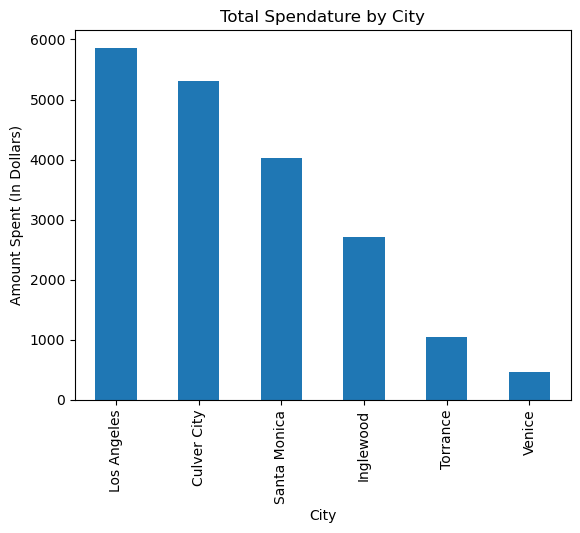

In [7]:
df_city.plot(x="city", y="total_spend", kind="bar", legend=False)
# sns.barplot(data="df_city", x="city", y="total_spend")
plt.title("Total Spendature by City")
plt.xlabel("City")
plt.ylabel("Amount Spent (In Dollars)")
plt.show()

What is the number of orders purchased from each city?

In [ ]:
city_orders_query = '''
SELECT c.city, COUNT(o.category) as num_of_orders
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
GROUP BY c.city
ORDER BY num_of_orders DESC
'''

df_orders_city = pd.read_sql(city_orders_query, con)

print(df_orders_city)

           city  num_of_orders
0   Culver City             58
1   Los Angeles             46
2  Santa Monica             42
3     Inglewood             27
4      Torrance             14
5        Venice              8


The above table shows how many order have come from each city. In summary:
Culver City - 58
Los Angeles - 46
Santa Monica - 42
Inglewood - 27
Torrance - 14
Venice - 8

I would not want for the public to be able to see people's names associated to what city they are from/in. This information could be used as a starting point to finding/stalking a person if fallen into the wrong hands. 

https://github.com/skeown13/cs82a-data-science-portfolio